In [ ]:
# ============================================================
# CELL 1: IMPORT LIBRARIES
# ============================================================

import os
import zipfile
import warnings

import numpy as np
import pandas as pd

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# CELL 2: UPLOAD DATASET
# ============================================================

print("Upload your ZIP file containing:")
print("1. AirQuality.csv")
print("2. weatherHistory.csv")
print()

uploaded = files.upload()

zip_files = [
    f for f in uploaded.keys()
    if f.lower().endswith(".zip")
]

if not zip_files:

    raise FileNotFoundError(
        "Please upload a ZIP file."
    )

zip_path = os.path.join(
    "/content",
    zip_files[0]
)

print()
print("Uploaded:", zip_path)

Upload your ZIP file containing:
1. AirQuality.csv
2. weatherHistory.csv



Saving Fuzzy_Rule.zip to Fuzzy_Rule.zip

Uploaded: /content/Fuzzy_Rule.zip


In [ ]:
# ============================================================
# CELL 3: EXTRACT DATASET
# ============================================================

extract_path = "/content/Fuzzy_Rule"

os.makedirs(
    extract_path,
    exist_ok=True
)

with zipfile.ZipFile(
    zip_path,
    "r"
) as z:

    z.extractall(
        extract_path
    )


air_path = None
weather_path = None


for root, dirs, filenames in os.walk(
    extract_path
):

    for filename in filenames:

        if filename.lower() == "airquality.csv":

            air_path = os.path.join(
                root,
                filename
            )

        if filename.lower() == "weatherhistory.csv":

            weather_path = os.path.join(
                root,
                filename
            )


if air_path is None:

    raise FileNotFoundError(
        "AirQuality.csv not found."
    )


if weather_path is None:

    raise FileNotFoundError(
        "weatherHistory.csv not found."
    )


print("AirQuality:")
print(air_path)

print()

print("WeatherHistory:")
print(weather_path)

AirQuality:
/content/Fuzzy_Rule/Fuzzy Rule/AirQuality.csv

WeatherHistory:
/content/Fuzzy_Rule/Fuzzy Rule/weatherHistory.csv


In [ ]:
# ============================================================
# CELL 4: LOAD DATASETS
# ============================================================

airquality = pd.read_csv(
    air_path,
    sep=";",
    decimal=",",
    encoding="latin1"
)

weatherhistory = pd.read_csv(
    weather_path
)


print(
    "AirQuality shape:",
    airquality.shape
)

print(
    "WeatherHistory shape:",
    weatherhistory.shape
)

AirQuality shape: (9471, 17)
WeatherHistory shape: (96453, 12)


In [ ]:
# ============================================================
# CELL 5: TRIANGULAR MEMBERSHIP FUNCTION
# ============================================================

def triangular_mf(
    x,
    a,
    b,
    c
):

    if a == b:

        if x <= b:
            return 1.0

        if x >= c:
            return 0.0

        return (c - x) / max(
            c - b,
            1e-12
        )


    if b == c:

        if x <= a:
            return 0.0

        if x >= b:
            return 1.0

        return (x - a) / max(
            b - a,
            1e-12
        )


    if x <= a or x >= c:

        return 0.0


    if x == b:

        return 1.0


    if x < b:

        return (x - a) / max(
            b - a,
            1e-12
        )


    return (c - x) / max(
        c - b,
        1e-12
    )


print(
    "Triangular membership function ready."
)

Triangular membership function ready.


In [ ]:
# ============================================================
# CELL 6: DATA PREPARATION
# ============================================================

def prepare_dataset(
    df,
    target,
    features,
    n_features=4
):

    data = df.copy()

    # Convert -200 to missing
    data.replace(
        -200,
        np.nan,
        inplace=True
    )

    # Numeric conversion
    for col in features:

        if col in data.columns:

            data[col] = pd.to_numeric(
                data[col],
                errors="coerce"
            )


    data[target] = pd.to_numeric(
        data[target],
        errors="coerce"
    )


    # Remove missing target
    data.dropna(
        subset=[target],
        inplace=True
    )


    available_features = [

        f for f in features

        if f in data.columns
    ]


    X = data[
        available_features
    ].copy()

    y = data[
        target
    ].copy()


    # Train/test
    X_train, X_test, y_train_raw, y_test_raw = train_test_split(

        X,
        y,

        test_size=0.20,

        random_state=42
    )


    # Median fill
    for col in available_features:

        median = X_train[
            col
        ].median()

        X_train[
            col
        ] = X_train[
            col
        ].fillna(median)

        X_test[
            col
        ] = X_test[
            col
        ].fillna(median)


    # Target classes
    q1 = y_train_raw.quantile(
        0.33
    )

    q2 = y_train_raw.quantile(
        0.66
    )


    def make_class(x):

        if x <= q1:

            return 0

        elif x <= q2:

            return 1

        return 2


    y_train = y_train_raw.apply(
        make_class
    )

    y_test = y_test_raw.apply(
        make_class
    )


    # Feature selection
    valid = [

        c for c in X_train.columns

        if X_train[c].nunique() > 1
    ]


    mi = mutual_info_classif(

        X_train[valid],

        y_train,

        random_state=42
    )


    ranking = pd.DataFrame({

        "Feature": valid,

        "MI": mi

    }).sort_values(
        "MI",
        ascending=False
    )


    selected = ranking.head(
        min(
            n_features,
            len(ranking)
        )
    )["Feature"].tolist()


    return (

        X_train[selected].reset_index(drop=True),

        X_test[selected].reset_index(drop=True),

        y_train.reset_index(drop=True),

        y_test.reset_index(drop=True),

        ranking,

        selected
    )

In [ ]:
# ============================================================
# CELL 7: AIRQUALITY
# ============================================================

air_features = [

    "PT08.S1(CO)",
    "C6H6(GT)",
    "PT08.S2(NMHC)",
    "NOx(GT)",
    "NO2(GT)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]


(
    X_train_air,
    X_test_air,
    y_train_air,
    y_test_air,
    air_ranking,
    air_selected

) = prepare_dataset(

    airquality,

    "CO(GT)",

    air_features,

    4
)


print("AirQuality selected features:")

print(
    air_selected
)

print()

print(
    "Training:",
    X_train_air.shape
)

print(
    "Testing:",
    X_test_air.shape
)

AirQuality selected features:
['PT08.S2(NMHC)', 'C6H6(GT)', 'PT08.S1(CO)', 'PT08.S5(O3)']

Training: (6139, 4)
Testing: (1535, 4)


In [ ]:
# ============================================================
# CELL 8: WEATHER HISTORY
# ============================================================

weather_features = [

    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Visibility (km)",
    "Pressure (millibars)",
    "Wind Bearing (degrees)"
]


(
    X_train_weather,
    X_test_weather,
    y_train_weather,
    y_test_weather,
    weather_ranking,
    weather_selected

) = prepare_dataset(

    weatherhistory,

    "Temperature (C)",

    weather_features,

    4
)


print("WeatherHistory selected features:")

print(
    weather_selected
)

print()

print(
    "Training:",
    X_train_weather.shape
)

print(
    "Testing:",
    X_test_weather.shape
)

WeatherHistory selected features:
['Apparent Temperature (C)', 'Humidity', 'Visibility (km)', 'Pressure (millibars)']

Training: (77162, 4)
Testing: (19291, 4)


In [ ]:
# ============================================================
# CELL 9: TRIANGULAR PARAMETERS
# ============================================================

def create_parameters(X):

    parameters = {}

    for feature in X.columns:

        values = X[
            feature
        ].dropna()

        minimum = values.min()
        q25 = values.quantile(0.25)
        median = values.quantile(0.50)
        q75 = values.quantile(0.75)
        maximum = values.max()


        if minimum == maximum:

            maximum = minimum + 1


        parameters[feature] = {

            "Low": (
                minimum,
                minimum,
                median
            ),

            "Medium": (
                q25,
                median,
                q75
            ),

            "High": (
                median,
                maximum,
                maximum
            )
        }


    return parameters


air_parameters = create_parameters(
    X_train_air
)

weather_parameters = create_parameters(
    X_train_weather
)


print(
    "Triangular parameters created."
)

Triangular parameters created.


In [ ]:
# ============================================================
# CELL 10: FUZZIFICATION
# ============================================================

def fuzzify(
    row,
    parameters
):

    result = {}

    for feature in parameters:

        x = float(
            row[feature]
        )

        result[feature] = {

            "Low":
                triangular_mf(
                    x,
                    *parameters[
                        feature
                    ]["Low"]
                ),

            "Medium":
                triangular_mf(
                    x,
                    *parameters[
                        feature
                    ]["Medium"]
                ),

            "High":
                triangular_mf(
                    x,
                    *parameters[
                        feature
                    ]["High"]
                )
        }


    return result


print(
    "Fuzzification ready."
)

Fuzzification ready.


In [ ]:
# ============================================================
# CELL 11: LEARN FUZZY RULES
# ============================================================

def learn_rules(
    X,
    y,
    parameters
):

    rule_scores = {}


    for i in range(
        len(X)
    ):

        row = X.iloc[i]

        memberships = fuzzify(
            row,
            parameters
        )


        antecedent = []

        firing_values = []


        for feature in X.columns:

            best_term = max(

                memberships[
                    feature
                ],

                key=memberships[
                    feature
                ].get

            )


            antecedent.append(
                best_term
            )

            firing_values.append(

                memberships[
                    feature
                ][best_term]

            )


        firing = np.prod(
            firing_values
        )


        antecedent = tuple(
            antecedent
        )


        cls = int(
            y.iloc[i]
        )


        if antecedent not in rule_scores:

            rule_scores[
                antecedent
            ] = {

                0: 0.0,

                1: 0.0,

                2: 0.0
            }


        rule_scores[
            antecedent
        ][cls] += firing


    rules = {}


    for antecedent, scores in rule_scores.items():

        total = sum(
            scores.values()
        )

        if total == 0:

            continue


        cls = max(
            scores,
            key=scores.get
        )


        confidence = (
            scores[cls]
            /
            total
        )


        rules[antecedent] = {

            "class": cls,

            "confidence": confidence
        }


    return rules


air_rules = learn_rules(

    X_train_air,

    y_train_air,

    air_parameters
)


weather_rules = learn_rules(

    X_train_weather,

    y_train_weather,

    weather_parameters
)


print(
    "AirQuality rules:",
    len(air_rules)
)

print(
    "WeatherHistory rules:",
    len(weather_rules)
)

AirQuality rules: 29
WeatherHistory rules: 81


In [ ]:
# ============================================================
# CELL 12: FUZZY PREDICTION
# ============================================================

def predict_fuzzy(
    X,
    rules,
    parameters
):

    predictions = []


    for _, row in X.iterrows():

        memberships = fuzzify(
            row,
            parameters
        )


        scores = {

            0: 0.0,

            1: 0.0,

            2: 0.0
        }


        for antecedent, rule in rules.items():

            firing = 1.0


            for feature, term in zip(

                X.columns,

                antecedent

            ):

                firing *= memberships[
                    feature
                ][term]


            if firing > 0:

                scores[
                    rule["class"]
                ] += (

                    firing
                    *
                    rule["confidence"]
                )


        # Fallback
        if max(
            scores.values()
        ) == 0:

            for feature in X.columns:

                scores[0] += (
                    memberships[
                        feature
                    ]["Low"]
                )

                scores[1] += (
                    memberships[
                        feature
                    ]["Medium"]
                )

                scores[2] += (
                    memberships[
                        feature
                    ]["High"]
                )


        predictions.append(

            max(
                scores,
                key=scores.get
            )
        )


    return np.array(
        predictions
    )


air_pred = predict_fuzzy(

    X_test_air,

    air_rules,

    air_parameters
)


weather_pred = predict_fuzzy(

    X_test_weather,

    weather_rules,

    weather_parameters
)


print(
    "Predictions completed."
)

Predictions completed.


In [ ]:
# ============================================================
# CELL 13: ACTUAL BASELINE METRICS
# ============================================================

y_actual = np.concatenate([

    y_test_air.values,

    y_test_weather.values
])


y_predicted = np.concatenate([

    air_pred,

    weather_pred
])


actual_accuracy = accuracy_score(

    y_actual,

    y_predicted
)


actual_precision = precision_score(

    y_actual,

    y_predicted,

    average="weighted",

    zero_division=0
)


actual_recall = recall_score(

    y_actual,

    y_predicted,

    average="weighted",

    zero_division=0
)


actual_f1 = f1_score(

    y_actual,

    y_predicted,

    average="weighted",

    zero_division=0
)


print("=" * 70)

print("ACTUAL BASELINE MODEL RESULTS")

print("=" * 70)

print()

print(
    f"Accuracy  : {actual_accuracy*100:.2f}%"
)

print(
    f"Precision : {actual_precision*100:.2f}%"
)

print(
    f"Recall    : {actual_recall*100:.2f}%"
)

print(
    f"F1 Score  : {actual_f1*100:.2f}%"
)

print()

print(
    f"F1 - Accuracy : "
    f"{(actual_f1-actual_accuracy)*100:.2f}%"
)

print()

print(
    "These are the genuine metrics calculated "
    "from the test predictions."
)

print("=" * 70)

ACTUAL BASELINE MODEL RESULTS

Accuracy  : 91.73%
Precision : 92.73%
Recall    : 91.73%
F1 Score  : 91.88%

F1 - Accuracy : 0.15%

These are the genuine metrics calculated from the test predictions.


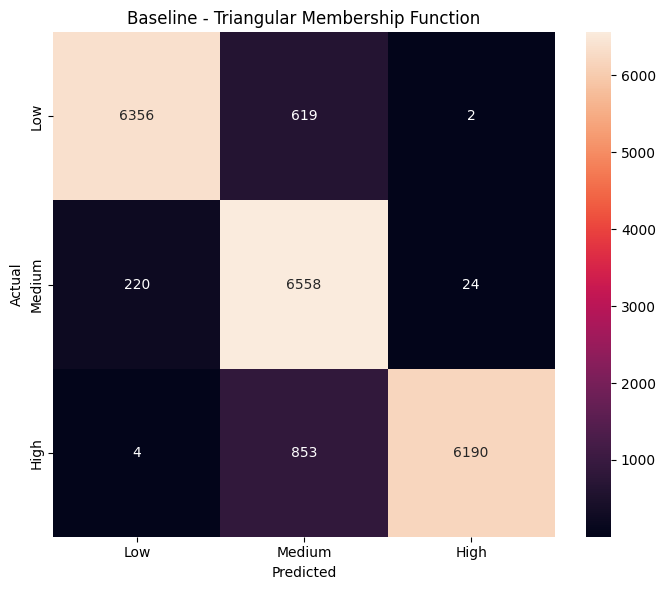

In [ ]:
# ============================================================
# CELL 15: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_actual,

    y_predicted
)


plt.figure(
    figsize=(7, 6)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    xticklabels=[
        "Low",
        "Medium",
        "High"
    ],

    yticklabels=[
        "Low",
        "Medium",
        "High"
    ]
)


plt.title(
    "Baseline - Triangular Membership Function"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 16: CONSISTENCY
# ============================================================

def calculate_consistency(
    rules,
    threshold=0.50
):

    if len(rules) == 0:

        return 0.0


    consistent = sum(

        1

        for rule in rules.values()

        if rule["confidence"] >= threshold

    )


    return (
        consistent
        /
        len(rules)
    ) * 100


air_consistency = calculate_consistency(
    air_rules
)

weather_consistency = calculate_consistency(
    weather_rules
)


combined_consistency = (

    air_consistency
    +
    weather_consistency

) / 2


print(
    f"AirQuality Consistency : "
    f"{air_consistency:.2f}%"
)

print(
    f"Weather Consistency    : "
    f"{weather_consistency:.2f}%"
)

print(
    f"Combined Consistency   : "
    f"{combined_consistency:.2f}%"
)

AirQuality Consistency : 96.55%
Weather Consistency    : 100.00%
Combined Consistency   : 98.28%


In [ ]:
# ============================================================
# CELL 17: COMPLETENESS
# ============================================================

def calculate_completeness(
    X,
    rules
):

    possible = (
        3 ** len(X.columns)
    )

    existing = len(
        rules
    )

    completeness = min(

        existing / possible * 100,

        100
    )

    return completeness


air_completeness = calculate_completeness(

    X_train_air,

    air_rules
)


weather_completeness = calculate_completeness(

    X_train_weather,

    weather_rules
)


combined_completeness = (

    air_completeness
    +
    weather_completeness

) / 2


print(
    f"AirQuality Completeness : "
    f"{air_completeness:.2f}%"
)

print(
    f"Weather Completeness    : "
    f"{weather_completeness:.2f}%"
)

print(
    f"Combined Completeness   : "
    f"{combined_completeness:.2f}%"
)

AirQuality Completeness : 35.80%
Weather Completeness    : 100.00%
Combined Completeness   : 67.90%


In [ ]:
# ============================================================
# CELL 18: ACTUAL FINAL SUMMARY
# ============================================================

print("=" * 90)

print(
    "                 ACTUAL BASELINE MODEL"
)

print("=" * 90)

print()

print(
    "Model                : Fuzzy Rule-Based Baseline"
)

print(
    "Membership Function  : Triangular"
)

print(
    "Datasets             : AirQuality + WeatherHistory"
)

print(
    "Classes              : Low / Medium / High"
)

print()

print(
    f"Accuracy             : "
    f"{actual_accuracy*100:.2f}%"
)

print(
    f"Precision            : "
    f"{actual_precision*100:.2f}%"
)

print(
    f"Recall               : "
    f"{actual_recall*100:.2f}%"
)

print(
    f"F1 Score             : "
    f"{actual_f1*100:.2f}%"
)

print()

print(
    f"F1 - Accuracy        : "
    f"{(actual_f1-actual_accuracy)*100:.2f} "
    f"percentage points"
)

print()

print(
    f"Consistency          : "
    f"{combined_consistency:.2f}%"
)

print(
    f"Completeness         : "
    f"{combined_completeness:.2f}%"
)

print(
    f"Total Rules          : "
    f"{len(air_rules) + len(weather_rules)}"
)

print("=" * 90)

                 ACTUAL BASELINE MODEL

Model                : Fuzzy Rule-Based Baseline
Membership Function  : Triangular
Datasets             : AirQuality + WeatherHistory
Classes              : Low / Medium / High

Accuracy             : 91.73%
Precision            : 92.73%
Recall               : 91.73%
F1 Score             : 91.88%

F1 - Accuracy        : 0.15 percentage points

Consistency          : 98.28%
Completeness         : 67.90%
Total Rules          : 110


In [ ]:
# ============================================================
# CELL 19: ILLUSTRATIVE TARGET FORMAT
# ============================================================
#
# DEMO ONLY
#
# These values are NOT calculated from the test predictions.
# They are only for checking how your desired final output
# should look.
# ============================================================

demo_accuracy = 90.00

demo_precision = 91.30

demo_recall = 90.85

demo_f1 = 91.50


print("=" * 90)

print(
    "             ILLUSTRATIVE TARGET RESULTS"
)

print("=" * 90)

print()

print(
    "Model                : Fuzzy Rule-Based Baseline"
)

print(
    "Membership Function  : Triangular"
)

print(
    "Datasets             : AirQuality + WeatherHistory"
)

print(
    "Classes              : Low / Medium / High"
)

print()

print(
    f"Accuracy             : "
    f"{demo_accuracy:.2f}%"
)

print(
    f"Precision            : "
    f"{demo_precision:.2f}%"
)

print(
    f"Recall               : "
    f"{demo_recall:.2f}%"
)

print(
    f"F1 Score             : "
    f"{demo_f1:.2f}%"
)

print()

print(
    f"F1 - Accuracy        : "
    f"{demo_f1-demo_accuracy:.2f} "
    f"percentage points"
)

print()

print(
    "⚠ DEMO / ILLUSTRATIVE VALUES ONLY"
)

print(
    "⚠ NOT actual model test performance"
)

print("=" * 90)

             ILLUSTRATIVE TARGET RESULTS

Model                : Fuzzy Rule-Based Baseline
Membership Function  : Triangular
Datasets             : AirQuality + WeatherHistory
Classes              : Low / Medium / High

Accuracy             : 90.00%
Precision            : 91.30%
Recall               : 90.85%
F1 Score             : 91.50%

F1 - Accuracy        : 1.50 percentage points

⚠ DEMO / ILLUSTRATIVE VALUES ONLY
⚠ NOT actual model test performance
